# Loading a cosmological simulation

A quickstart guide to loading the simulation

In [1]:
import yt
import unyt
from astropy.table import Table
import helper_functions as hf
import numpy as np
import matplotlib.pyplot as plt
import se_functions
import importlib

importlib.reload(se_functions)
from se_functions import find_bursts

In [2]:
final_output=116

# Load the timeseries of the most massive black hole

In [3]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

In [8]:
# Load position from file and count BH
filename=f'{df}/output_{str(final_output).zfill(5)}/sink_{str(final_output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")
order=np.argsort(t['BHmass'])[::-1]
second_id=t['sink_id'][order[1]]
thrid_id=t['sink_id'][order[2]]
fourth_id=t['sink_id'][order[3]]
most_massive_id=t['sink_id'][np.argmax(t['BHmass'])]
print("The most massive BH has id", most_massive_id, 'with mass of', t[t['sink_id'] == most_massive_id]['BHmass'])
print("The second most massive BH has id", second_id)
print("The thrid most massive BH has id", thrid_id)
print("The fourth most massive BH had id", fourth_id)


This output contains 684 black holes
The most massive BH has id 5 with mass of      BHmass     
----------------
2.3092291284e-11
The second most massive BH has id 36
The thrid most massive BH has id 27
The fourth most massive BH had id 25


# Plot evolution of most massive BH

In [5]:
# Load timeseries for most massive black hole
ts=hf.SinkDataLoader(df,sinkid=thrid_id)

for c in ts.data.colnames:
    print(c, ts.data[c].unit, ts.data[c].shape)


nstep None (131750,)
aexp None (131750,)
time Gyr (131750,)
BHmass solMass (131750,)
position pc (131750, 3)
vsink km / s (131750, 3)
dotMbondi solMass / yr (131750,)
dotMedd solMass / yr (131750,)
rg_scale pc (131750,)
spinmag None (131750,)
dMgrowth solMass (131750,)
dMaccr solMass (131750,)
Esave erg (131750,)
bhspin None (131750, 3)
jsink None (131750, 3)
Efeed erg (131750,)
f_edd None (131750,)
eps_sink None (131750,)
eta_disk None (131750,)
eta_jet None (131750,)
Mass_loading_factor None (131750,)
Rb pc (131750,)
Ra pc (131750,)
Rbhl pc (131750,)
Rbhl_cell pc (131750,)
Ra_cell pc (131750,)
Rb_cell pc (131750,)
dtnew yr (131750,)
dotMgrowth solMass / yr (131750,)
dotMaccr solMass / yr (131750,)
Efeed_Th erg (131750,)
Efeed_Ki erg (131750,)
alpha_madau None (131750,)
beta_eff None (131750,)
z None (131750,)


In [6]:
time=Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt',format='ascii')

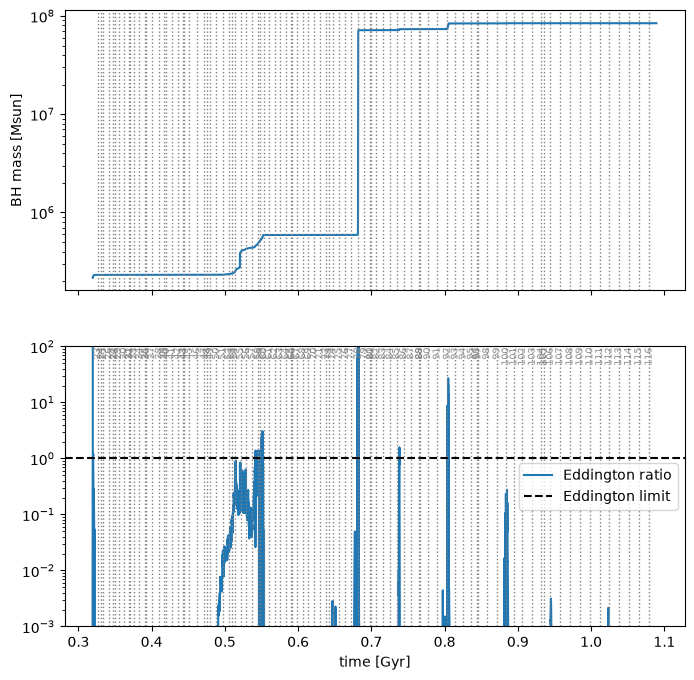

In [7]:
# Full timeseries
fig,axes=plt.subplots(2,1,figsize=(8,8),sharex=True)

# Time window to display (Gyr)
# Edit these values to change the plotted time range
tmin=ts.data['time'][0]  # Start time (Gyr)
tmax=ts.data['time'][-1]  # End time (Gyr)

#tmin = 0.365 #Comment out for whole timeseries
#tmax = 0.38  # Comment out for whole timeseries

# Plot mass (only inside [tmin,tmax])
ax = axes[0]
times = ts.data['time']
mask = (times >= tmin) & (times <= tmax)
ax.plot(times[mask], ts.data['BHmass'][mask], label='BH mass')
ax.set_yscale('log')
ax.set_ylabel('BH mass [Msun]')

# Plot Eddington ratios (only inside [tmin,tmax])
ax = axes[1]
ratio = ts.data['dotMaccr']/ts.data['dotMedd']
ax.plot(times[mask], ratio[mask], label='Eddington ratio')
ax.axhline(1.0, ls='--', color='k', label='Eddington limit')
ax.set_yscale('log')
ax.legend()

# Add output times and redshifts
axes[-1].set_xlabel('time [Gyr]')

# Draw vertical dotted grey lines at each output time from the `time` table (ensure units are Gyr)
try:
    # If `time` is an astropy Table with a column 'time' that may have units
    output_times = time['time']
    # If entries are yt or unyt quantities, convert to float in Gyr
    try:
        output_times_gyr = [t.to('Gyr').v if hasattr(t,'to') else float(t) for t in output_times]
    except Exception:
        # Fallback: assume column already in Gyr or plain numbers
        output_times_gyr = [float(t) for t in output_times]

    # Assume the table has an `output` column containing integer output numbers
    outputs = [int(o) for o in time['output']]
    outputs_labels = [str(o) for o in outputs]
    axes[-1].set_ylim([1e-3,1e2])

    # Draw lines and small grey rotated labels aligned with the vertical lines
    ymin0, ymax0 = axes[0].get_ylim()
    ymin1, ymax1 = axes[1].get_ylim()
    # place labels near the top of the lower subplot (axes[1])
    label_y = ymax1 * 0.95

    # Only show output lines/labels that fall inside [tmin, tmax]
    visible = [(ot, lbl) for ot, lbl in zip(output_times_gyr, outputs_labels) if (ot >= tmin and ot <= tmax)]
    for ot, lbl in visible:
        axes[0].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].text(ot, label_y, lbl, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)
except Exception as e:
    print('Could not draw output-time vertical lines and labels:', e)

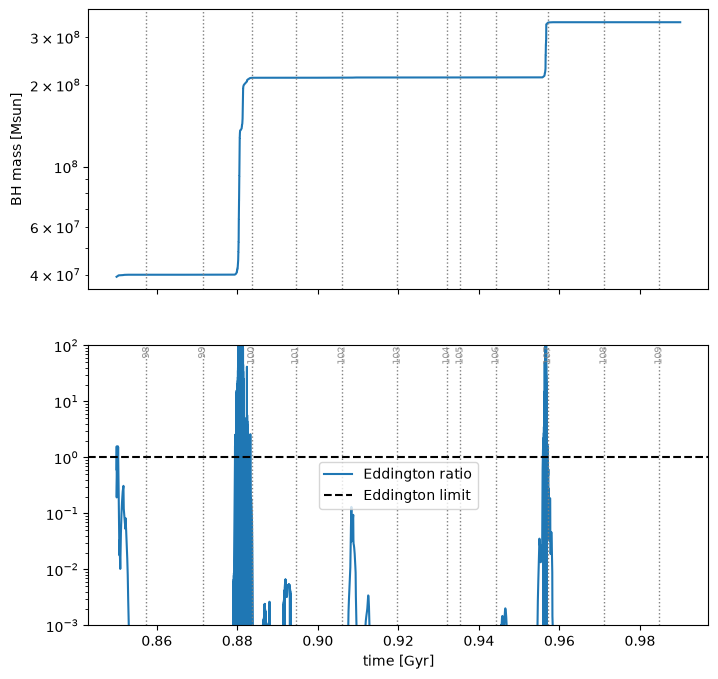

In [22]:
# Full timeseries
fig,axes=plt.subplots(2,1,figsize=(8,8),sharex=True)

# Time window to display (Gyr)
# Edit these values to change the plotted time range
tmin=ts.data['time'][0]  # Start time (Gyr)
tmax=ts.data['time'][-1]  # End time (Gyr)

# For the most massive BH
tmin = 0.85  #Comment out for whole timeseries
tmax = 0.99  # Comment out for whole timeseries


# For the second massive BH
# tmin = 0.53
# tmax = 0.58


# Plot mass (only inside [tmin,tmax])
ax = axes[0]
times = ts.data['time']
mask = (times >= tmin) & (times <= tmax)
ax.plot(times[mask], ts.data['BHmass'][mask], label='BH mass')
ax.set_yscale('log')
ax.set_ylabel('BH mass [Msun]')

# Plot Eddington ratios (only inside [tmin,tmax])
ax = axes[1]
ratio = ts.data['dotMaccr']/ts.data['dotMedd']
ax.plot(times[mask], ratio[mask], label='Eddington ratio')
ax.axhline(1.0, ls='--', color='k', label='Eddington limit')
ax.set_yscale('log')
ax.legend()

# Add output times and redshifts
axes[-1].set_xlabel('time [Gyr]')

# Draw vertical dotted grey lines at each output time from the `time` table (ensure units are Gyr)
try:
    # If `time` is an astropy Table with a column 'time' that may have units
    output_times = time['time']
    # If entries are yt or unyt quantities, convert to float in Gyr
    try:
        output_times_gyr = [t.to('Gyr').v if hasattr(t,'to') else float(t) for t in output_times]
    except Exception:
        # Fallback: assume column already in Gyr or plain numbers
        output_times_gyr = [float(t) for t in output_times]

    # Assume the table has an `output` column containing integer output numbers
    outputs = [int(o) for o in time['output']]
    outputs_labels = [str(o) for o in outputs]
    axes[-1].set_ylim([1e-3,1e2])

    # Draw lines and small grey rotated labels aligned with the vertical lines
    ymin0, ymax0 = axes[0].get_ylim()
    ymin1, ymax1 = axes[1].get_ylim()
    # place labels near the top of the lower subplot (axes[1])
    label_y = ymax1 * 0.95

    # Only show output lines/labels that fall inside [tmin, tmax]
    visible = [(ot, lbl) for ot, lbl in zip(output_times_gyr, outputs_labels) if (ot >= tmin and ot <= tmax)]
    for ot, lbl in visible:
        axes[0].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].text(ot, label_y, lbl, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)
except Exception as e:
    print('Could not draw output-time vertical lines and labels:', e)

# Generate super-Eddington Catalogue

In [8]:
b = find_bursts(ts.data, gap_myr=0.2, min_dur_myr=0.1)
print(len(b))
b.sort('dM_accr', reverse=True)
b[:10]


6


i_start,i_end,t_start_myr,t_end_myr,duration_myr,z_start,z_end,aexp_start,aexp_end,M_start,M_end,dM_accr,E_feed,E_feed_Th,E_feed_Ki,f_edd_max,dM_edd_max
int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
121429,121503,1065.4262354760558,1065.9601288618794,0.5338933858236032,5.416318355349529,5.414169639873875,0.155852615879987,0.155904825744469,53728647.9211721,88537406.9672677,34892971.13612306,6.945214672883276e+52,0.0,6.945214672883276e+52,3.38420829380877,166.3658208763605
64496,64949,721.3785265432382,723.4640805021751,2.0855539589368846,7.325605055806319,7.309576097532574,0.120111390499192,0.12034308227792,21536140.9868219,48302878.6922954,26772445.34825406,0.0,0.0,0.0,2.97338810113215,70.00195879304685
21425,22676,545.501465366637,550.2673077030012,4.7658423363641305,9.032478023905576,8.974423289371778,0.099676271168218,0.100256422951846,272183.343319632,20980016.8812149,20707914.822105072,1.9059440124127865e+59,3.388681767886058e+57,6.477277185684294e+57,3.0910119875665,89.09056707076275
105682,105743,959.4063533827521,959.8454656023467,0.4391122195946764,5.881941991500776,5.879838075497541,0.145307821721689,0.145352258152919,50677362.2012571,53315518.503769,2654621.940444223,0.0,0.0,0.0,2.39391544067327,19.862964197465306
79649,79739,805.3665877731881,805.9332379851401,0.5666502119519237,6.735392025585409,6.731759873613134,0.12927593025569,0.129336660261888,48766158.871571,50127343.6732876,1377566.3046322523,0.0,0.0,0.0,1.61305071077261,4.149237122358235
0,278,369.60847177294676,371.4680292111521,1.8595574382053428,12.00676591495535,11.963307038759673,0.076883062748918,0.077140809595117,104785.415832857,195139.143940773,95139.14394077258,0.0,0.0,0.0,3.10912173492541,90.49524677168618


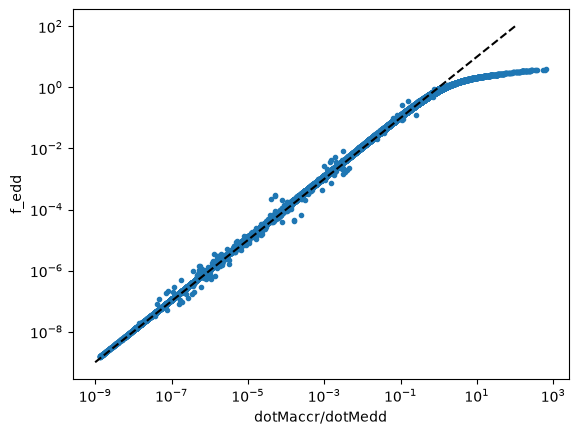

In [29]:
ratio = ts.data['dotMaccr'] / ts.data['dotMedd']
m = ratio > 0
plt.loglog(ratio[m], ts.data['f_edd'][m], ".")
plt.plot([1e-9, 1e2], [1e-9, 1e2], 'k--')
plt.xlabel('dotMaccr/dotMedd')
plt.ylabel('f_edd');

# Load a dataset

In [7]:
output=102

In [8]:
ds=yt.load(hf.info_file(output,df))

print(ds.field_list)
print(ds.particle_types)

print(ds.parameters['levelmax'])

# print(ds.index.get_smallest_dx().in_units('pc'))
# print(ds.index.get_smallest_dx().in_units('pccm'))

# ds.field_list
# ds.derived_field_list

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt


yt : [INFO     ] 2026-10-27 22:43:43,303 Parameters: current_time              = 0.9059702647248421 Gyr
yt : [INFO     ] 2026-10-27 22:43:43,305 Parameters: domain_dimensions         = [128 128 128]
yt : [INFO     ] 2026-10-27 22:43:43,305 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-10-27 22:43:43,307 Parameters: domain_right_edge         = [1. 1. 1.]
yt : [INFO     ] 2026-10-27 22:43:43,307 Parameters: cosmological_simulation   = True
yt : [INFO     ] 2026-10-27 22:43:43,308 Parameters: current_redshift          = 6.150552736644741
yt : [INFO     ] 2026-10-27 22:43:43,309 Parameters: omega_lambda              = 0.693499982357025
yt : [INFO     ] 2026-10-27 22:43:43,309 Parameters: omega_matter              = 0.306499987840652
yt : [INFO     ] 2026-10-27 22:43:43,310 Parameters: omega_radiation           = 0.0
yt : [INFO     ] 2026-10-27 22:43:43,310 Parameters: hubble_constant           = 0.6790000152587891
yt : [INFO     ] 2026-10-27 22:43:45,386 Adding p

[('gravity', 'Potential'), ('gravity', 'x-acceleration'), ('gravity', 'y-acceleration'), ('gravity', 'z-acceleration'), ('io', 'conformal_birth_time'), ('io', 'particle_birth_time'), ('io', 'particle_family'), ('io', 'particle_identity'), ('io', 'particle_level'), ('io', 'particle_mass'), ('io', 'particle_metallicity'), ('io', 'particle_position_x'), ('io', 'particle_position_y'), ('io', 'particle_position_z'), ('io', 'particle_tag'), ('io', 'particle_velocity_x'), ('io', 'particle_velocity_y'), ('io', 'particle_velocity_z'), ('nbody', 'particle_birth_time'), ('nbody', 'particle_mass'), ('nbody', 'particle_position_x'), ('nbody', 'particle_position_y'), ('nbody', 'particle_position_z'), ('nbody', 'particle_velocity_x'), ('nbody', 'particle_velocity_y'), ('nbody', 'particle_velocity_z'), ('ramses', 'Density'), ('ramses', 'Metallicity'), ('ramses', 'Pressure'), ('ramses', 'hydro_scalar_01'), ('ramses', 'x-velocity'), ('ramses', 'y-velocity'), ('ramses', 'z-velocity'), ('sink', 'BH_bondi_

In [9]:
ad=ds.all_data() # Load a data object that contains all data

print(np.unique(ad['DM', 'particle_mass'].to('Msun')))

yt : [INFO     ] 2026-10-27 22:43:58,473 Identified   512/  512 intersecting domains (  512 through hilbert key indexing)


[3.02381259e+06 2.41905007e+07 1.93524006e+08 1.54819205e+09
 1.23855364e+10 9.90842911e+10 7.92674328e+11 6.34139463e+12] Msun


In [14]:
print("The current redshift is",ds.current_redshift) #Load some information on the output


The current redshift is 6.4184959165479745


In [15]:
print("The whole box has a size of",ds.length_unit.in_units('Mpc'))

The whole box has a size of 99.07966580046096 Mpc


# Plot the whole box and annotate black holes

yt : [INFO     ] 2026-10-14 20:25:06,933 Projection completed
yt : [INFO     ] 2026-10-14 20:25:06,940 xlim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,940 ylim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,943 xlim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,943 ylim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,946 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-10-14 20:25:09,307 Identified   512/  512 intersecting domains (  512 through hilbert key indexing)



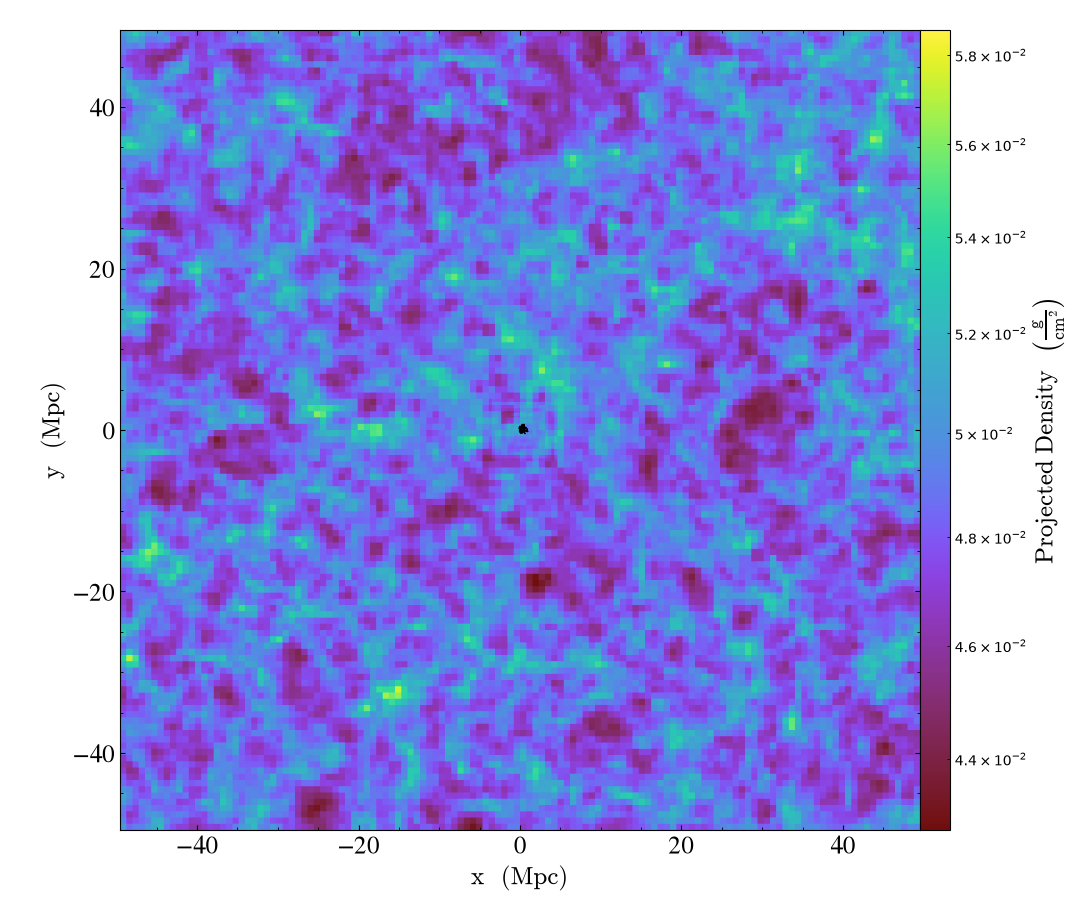

In [16]:
p=yt.ProjectionPlot(ds,normal='z',fields=['density'])
p.annotate_particles(width=ds.length_unit,ptype='sink')
p.show()

# Plot central 1 Mpc and annotate BH

yt : [INFO     ] 2026-10-27 22:44:34,901 Identified   504/  512 intersecting domains (  504 through hilbert key indexing)
yt : [INFO     ] 2026-10-27 22:45:34,014 Projection completed
yt : [INFO     ] 2026-10-27 22:45:34,022 xlim = 0.495136 0.504864
yt : [INFO     ] 2026-10-27 22:45:34,023 ylim = 0.495136 0.504864
yt : [INFO     ] 2026-10-27 22:45:34,027 xlim = 0.495136 0.504864
yt : [INFO     ] 2026-10-27 22:45:34,027 ylim = 0.495136 0.504864
yt : [INFO     ] 2026-10-27 22:45:34,032 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-10-27 22:45:37,257 Identified   418/  512 intersecting domains (  504 through hilbert key indexing)



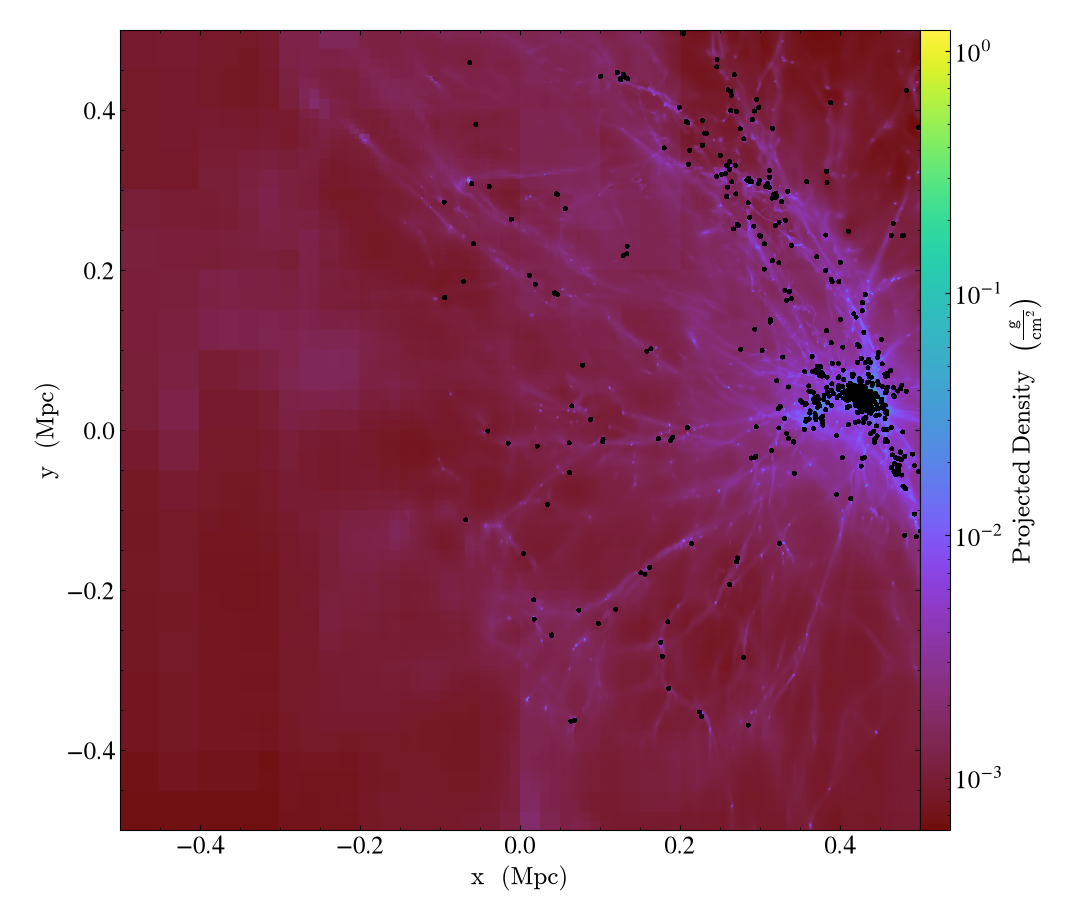

In [10]:
width=ds.quan(1,'Mpc')  #Width of your plot
region=ds.sphere(ds.arr([0.5,0.5,0.5],'code_length'),width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region)
p.annotate_particles(width=width*2,ptype='cloud',data_source=region,p_size=5)
p.show()

# Center plot on sink number 5

In [11]:
target_sink=5

In [12]:
# Load position from file at this output
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

This output contains 661 black holes


In [13]:
# Find position of target BH
sink_pos=t[t['sink_id']==target_sink]['x','y','z'] # Position on 6th sink
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length') #Position converted to something the dataset understands by adding units and stripping formatting

yt : [INFO     ] 2026-10-27 22:46:05,170 Identified   272/  512 intersecting domains (  447 through hilbert key indexing)
yt : [INFO     ] 2026-10-27 22:46:10,664 Projection completed
yt : [INFO     ] 2026-10-27 22:46:10,666 xlim = 0.502683 0.505602
yt : [INFO     ] 2026-10-27 22:46:10,666 ylim = 0.498948 0.501867
yt : [INFO     ] 2026-10-27 22:46:10,669 xlim = 0.502683 0.505602
yt : [INFO     ] 2026-10-27 22:46:10,670 ylim = 0.498948 0.501867
yt : [INFO     ] 2026-10-27 22:46:10,671 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-10-27 22:46:11,927 Identified   168/  512 intersecting domains (  237 through hilbert key indexing)



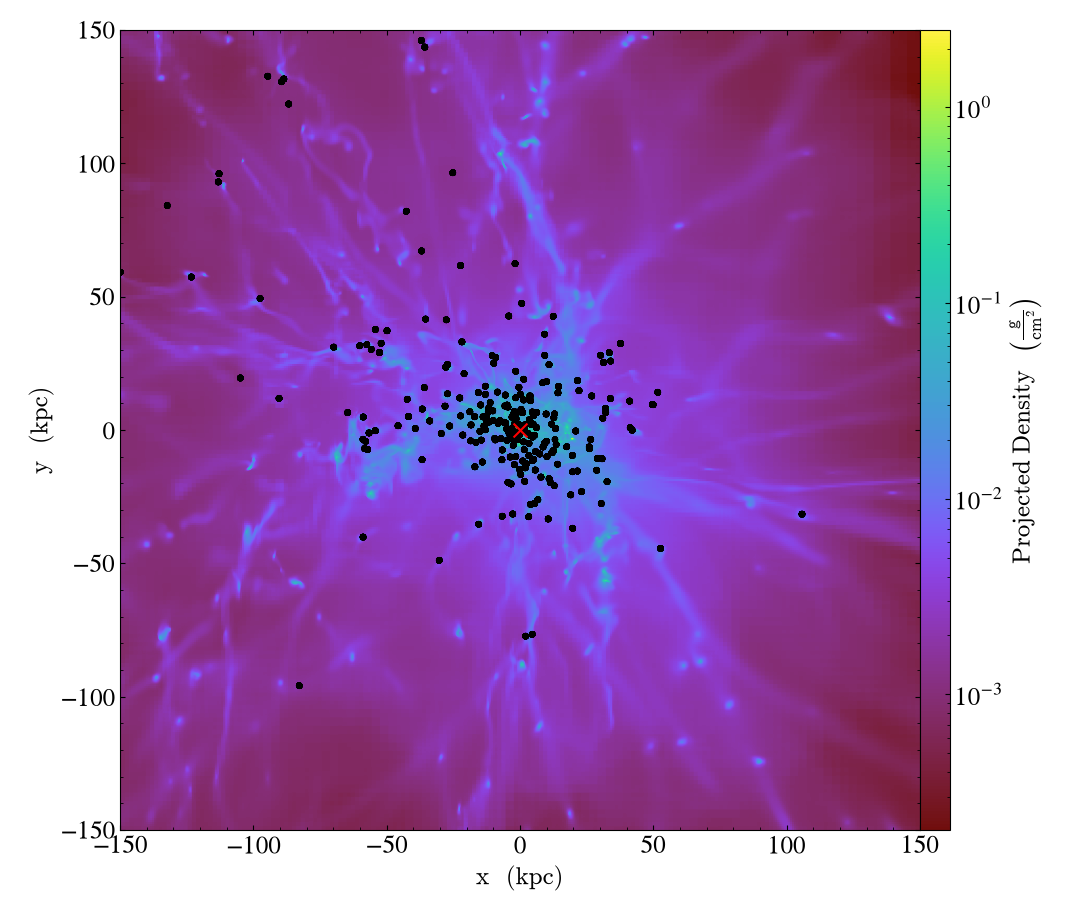

In [14]:
# Make plot centred on BH 17, zooming in to the central 300 kpc
width=ds.quan(300,'kpc')  #Width of your plot
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region,center=sink_pos_ds)
p.annotate_particles(width=width.in_units('code_length'),ptype='cloud',data_source=region,p_size=5)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

p.show()

yt : [INFO     ] 2026-10-27 22:46:50,120 Identified    42/  512 intersecting domains (   64 through hilbert key indexing)
yt : [INFO     ] 2026-10-27 22:46:50,532 Projection completed
yt : [INFO     ] 2026-10-27 22:46:50,533 xlim = 0.504045 0.504240
yt : [INFO     ] 2026-10-27 22:46:50,534 ylim = 0.500310 0.500505
yt : [INFO     ] 2026-10-27 22:46:50,537 xlim = 0.504045 0.504240
yt : [INFO     ] 2026-10-27 22:46:50,537 ylim = 0.500310 0.500505
yt : [INFO     ] 2026-10-27 22:46:50,539 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-10-27 22:46:52,160 Saving plot fig/most_massive/density_density_102_20.png



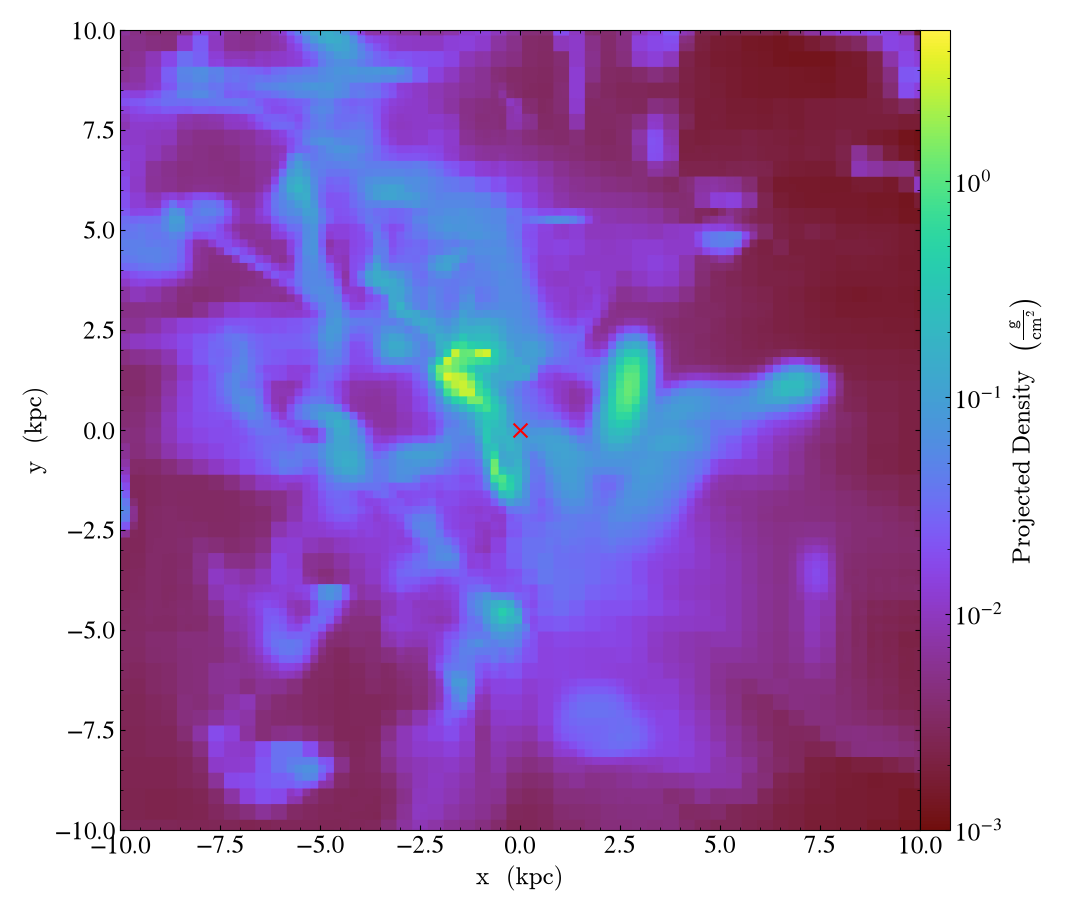

In [ ]:
# Make plot centred on BH 17, zooming in to the central 10 kpc
width = ds.quan(20, 'kpc')  # Width of your plot
region = ds.sphere(sink_pos_ds, width)  # Make a sphere with the data you want to plot
p = yt.ProjectionPlot(ds, normal='z', fields=['density'], width=width, data_source=region, center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)
p.set_zlim(('gas','density'), 1e-3, 5)

# p.save(f'fig/most_massive/density_density_{output:03d}_{width.value}.png')
p.show()

yt : [INFO     ] 2026-10-27 22:47:03,966 Identified    42/  512 intersecting domains (   64 through hilbert key indexing)
yt : [INFO     ] 2026-10-27 22:47:04,765 Projection completed
yt : [INFO     ] 2026-10-27 22:47:04,767 xlim = 0.504045 0.504240
yt : [INFO     ] 2026-10-27 22:47:04,767 ylim = 0.500310 0.500505
yt : [INFO     ] 2026-10-27 22:47:04,770 xlim = 0.504045 0.504240
yt : [INFO     ] 2026-10-27 22:47:04,771 ylim = 0.500310 0.500505
yt : [INFO     ] 2026-10-27 22:47:04,772 Making a fixed resolution buffer of (('gas', 'temperature')) 800 by 800
yt : [INFO     ] 2026-10-27 22:47:05,291 Saving plot fig/most_massive/tem_density_102_20.png



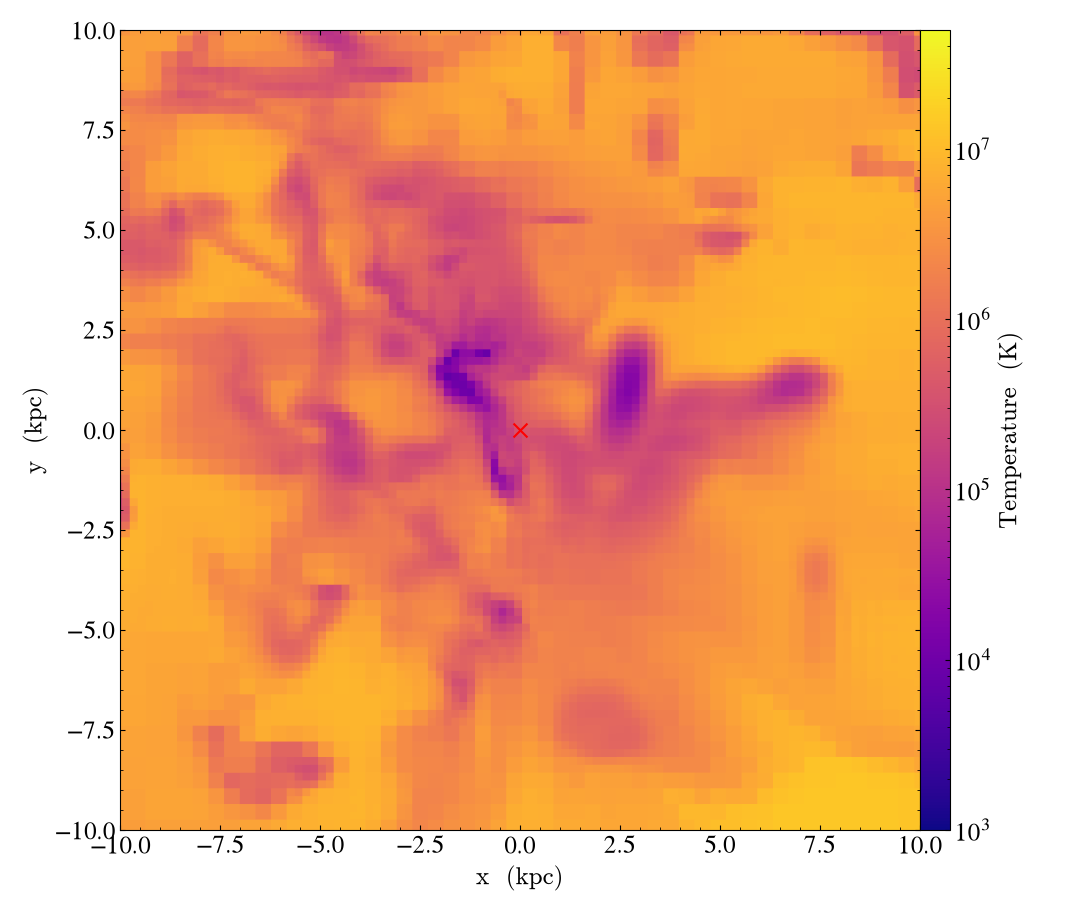

In [16]:
# Plot temperature instead, reusing the data objects
width=ds.quan(20,'kpc')
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['temperature'], weight_field=('gas','density'),
width=width,data_source=region,center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)
p.set_cmap('temperature', 'plasma')
p.set_zlim('temperature', 1e3, 5e7)

# p.save(f'fig/most_massive/tem_density_{output:03d}_{width.value}.png')
p.show()

In [24]:
sp = ds.sphere(sink_pos_ds, (5, 'kpc'))
E_th = (1.5 * sp['gas','pressure'] * sp['gas','cell_volume']).sum().to('erg')
print(E_th)

# 6.786206708326559e+56 erg for snapshot 099
# 7.676195514036063e+57 erg for snapshot 100

yt : [INFO     ] 2026-10-14 20:25:59,533 Identified    11/  512 intersecting domains (   23 through hilbert key indexing)


1.525823348474118e+57 erg


yt : [INFO     ] 2026-10-14 20:25:59,570 Identified 1 intersecting domains
yt : [INFO     ] 2026-10-14 20:26:00,010 Projection completed
yt : [INFO     ] 2026-10-14 20:26:00,012 xlim = 0.504075 0.504277
yt : [INFO     ] 2026-10-14 20:26:00,012 ylim = 0.500306 0.500508
yt : [INFO     ] 2026-10-14 20:26:00,015 xlim = 0.504075 0.504277
yt : [INFO     ] 2026-10-14 20:26:00,015 ylim = 0.500306 0.500508
yt : [INFO     ] 2026-10-14 20:26:00,016 Making a fixed resolution buffer of (('deposit', 'star_cic')) 800 by 800



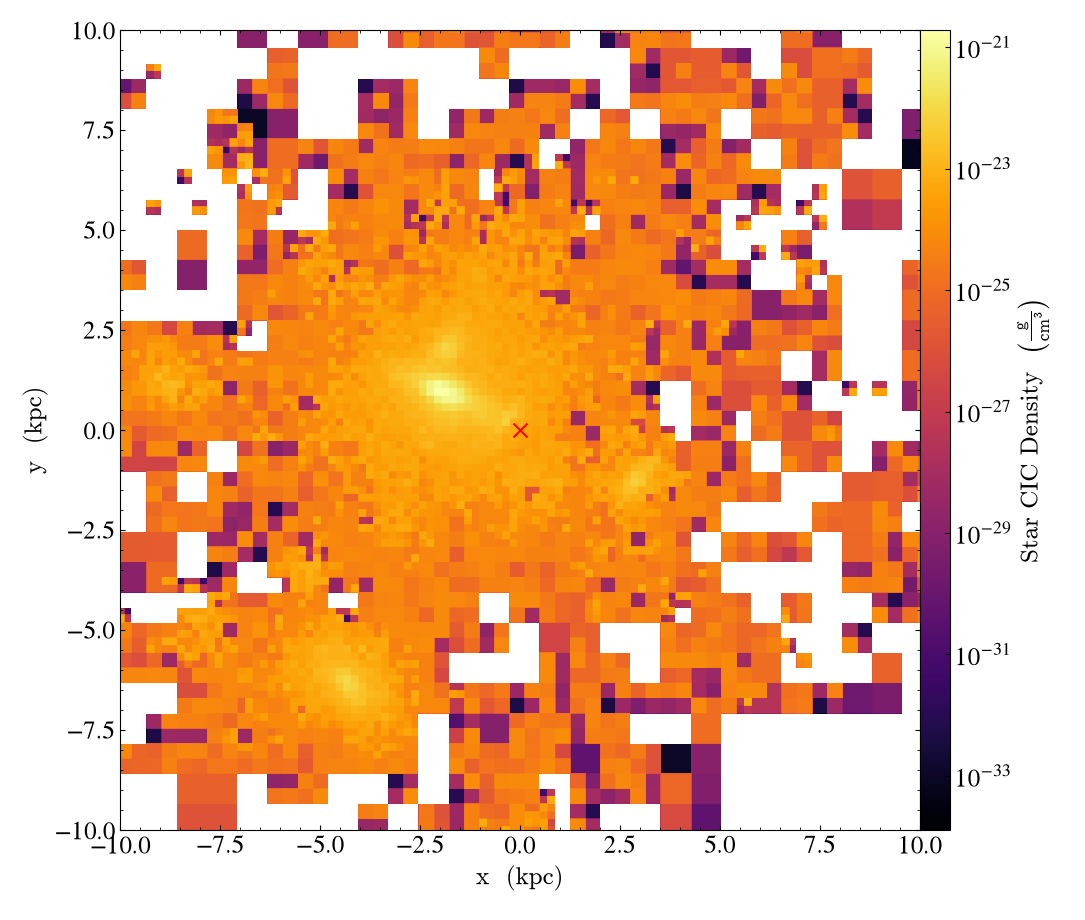

In [25]:
# Plot stellar distribution instead, reusing the data objects
field=('deposit','star_cic')
p = yt.ProjectionPlot(ds, normal='z', fields=[field],
                      width=width, data_source=region, 
                      center=sink_pos_ds,weight_field=field)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

# Use inferno colormap for the stellar field
p.set_cmap(field, 'inferno')

p.show()

# Measure gas properties within 1 kpc of sink 

In [26]:
sp=ds.sphere(sink_pos_ds,ds.quan(2,'kpc')) # Make a sphere with the data you want to plot
print("Maximum density within 2 kpc of sink 6:",sp['density'].max().in_units('g/cm**3'))
print("Maximum temperature within 2 kpc of sink 6:",sp['temperature'].max())
print("Total gas mass within 2 kpc of the sink",sp['mass'].sum().in_units('Msun'))

yt : [INFO     ] 2026-10-14 20:26:00,501 Identified     2/  512 intersecting domains (    6 through hilbert key indexing)


Maximum density within 2 kpc of sink 6: 4.968823707331805e-23 g/cm**3
Maximum temperature within 2 kpc of sink 6: 15219741.750834495 K
Total gas mass within 2 kpc of the sink 645714360.6570529 Msun


In [27]:
print("Maximum stellar mass in this sphere is",sp['star','particle_mass'].in_units('Msun').max())

Maximum stellar mass in this sphere is 1389473.8454110492 Msun


yt : [INFO     ] 2026-10-14 20:26:00,563 Identified    23/  512 intersecting domains (   32 through hilbert key indexing)


yt : [INFO     ] 2026-10-14 20:26:00,651 Projection completed
yt : [INFO     ] 2026-10-14 20:26:00,653 xlim = 0.504125 0.504226
yt : [INFO     ] 2026-10-14 20:26:00,653 ylim = 0.500357 0.500458
yt : [INFO     ] 2026-10-14 20:26:00,656 xlim = 0.504125 0.504226
yt : [INFO     ] 2026-10-14 20:26:00,656 ylim = 0.500357 0.500458
yt : [INFO     ] 2026-10-14 20:26:00,657 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



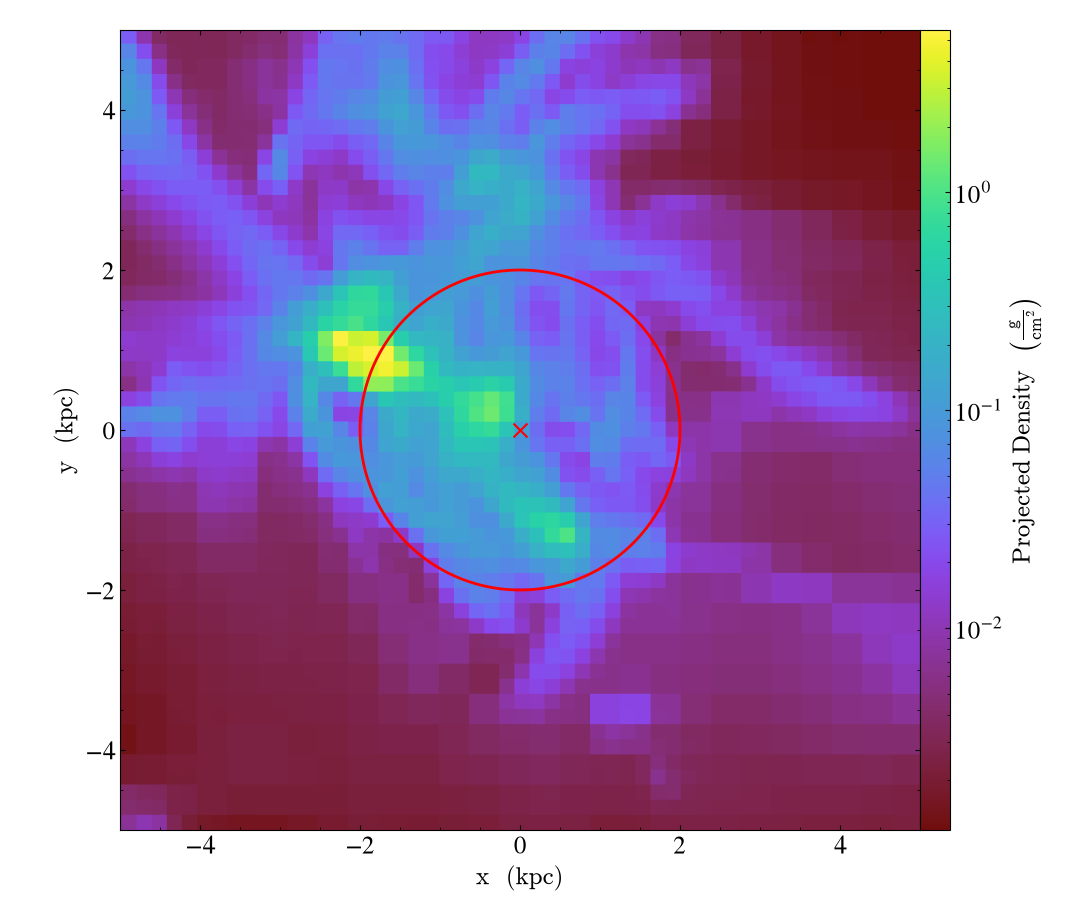

In [28]:
# Make plot centred on BH 17, zooming in to the central 10 kpc
width=ds.quan(10,'kpc')  #Width of your plot
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region,center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

# Annotate the sphere `sp` using yt's native annotation (handles coordinates/radius)
# Draw an unfilled red circle corresponding to the sphere projection
# pass styling via `circle_args` dict
p.annotate_sphere(sp.center, sp.radius, coord_system='data', circle_args={'color': 'red',  'linewidth': 2})

p.show()

In [11]:
from matplotlib import rc_context
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LogNorm
import matplotlib.animation as ma
import imageio_ffmpeg
plt.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()


In [5]:
width = (200, 'kpccm')
half  = width[0] / 2

target_sink = 5

time = Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt', format='ascii')
snap_t   = np.array([float(t) for t in time['time']])
snap_out = np.array([int(o) for o in time['output']])

frames = []
for out in snap_out:                              
    ds  = yt.load(hf.info_file(out, df))
    t   = Table.read(f'{df}/output_{out:05d}/sink_{out:05d}.csv', format='ascii',
                     names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    sel = t[t['sink_id'] == target_sink]
    if len(sel) == 0:
        continue
    row = sel[0]
    c   = ds.arr([row['x'], row['y'], row['z']], 'code_length')
    sp  = ds.sphere(c, width)
    prj = ds.proj(('gas','density'), 'z', center=c, data_source=sp)
    frb = prj.to_frb(width, 512, center=c)
    frames.append((frb[('gas','density')].to('g/cm**2').value, out, ds.current_redshift))
    print(out, end=' ')

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00001/info_00001.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00002/info_00002.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00003/info_00003.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00004/info_00004.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00005/info_00005.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00006/info_00006.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00007/info_00007.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00008/info_00008.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00009/info_00009.txt
9 Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00010/info_00010.txt
10 Openi

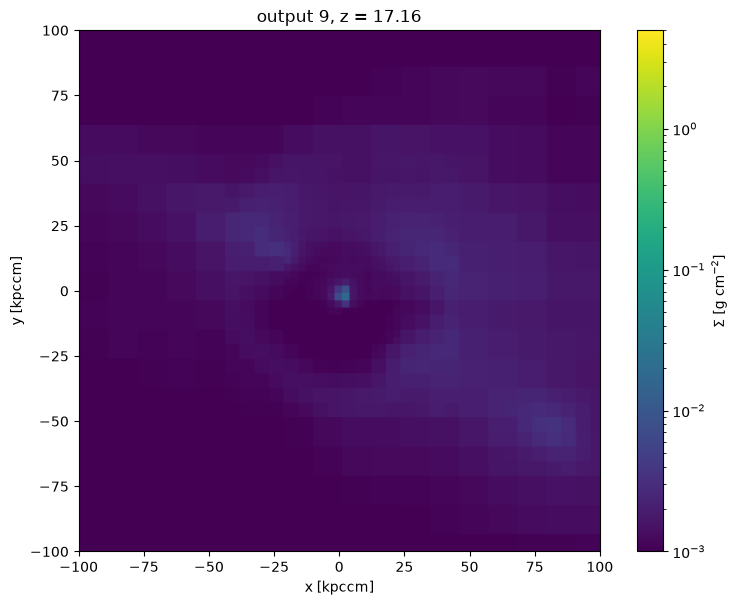

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(frames[0][0], origin='lower', extent=[-half, half, -half, half],
               norm=LogNorm(1e-3, 5), cmap='viridis')
fig.colorbar(im, label=r'$\Sigma$ [g cm$^{-2}$]')
ax.set_xlabel(f'x [{width[1]}]'); ax.set_ylabel(f'y [{width[1]}]')
title = ax.set_title('')

def animate(i):
    im.set_data(frames[i][0])
    title.set_text(f'output {frames[i][1]}, z = {frames[i][2]:.2f}')
    return im, title

anim = FuncAnimation(fig, animate, frames=len(frames), interval=200)
plt.tight_layout()

with rc_context({"mathtext.fontset": "stix"}):
    anim.save("animation.mp4")